In [38]:
import cv2
import numpy as np

img_bgr = cv2.imread('justphoto.jpg')

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)



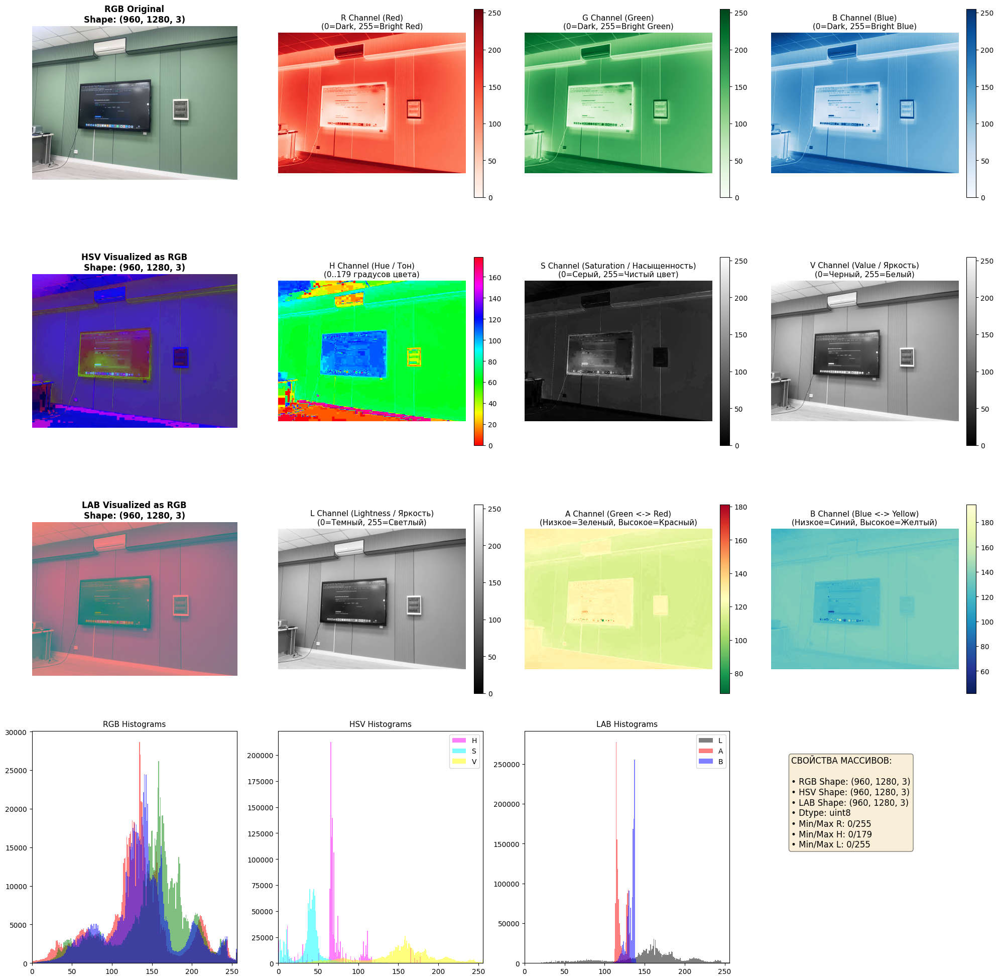

LAB shape: (960, 1280, 3)


array([[[240, 129, 121],
        [240, 129, 121],
        [240, 129, 121],
        ...,
        [108, 117, 134],
        [102, 117, 134],
        [ 92, 116, 134]],

       [[240, 129, 121],
        [240, 129, 121],
        [240, 129, 121],
        ...,
        [109, 117, 134],
        [103, 117, 134],
        [ 94, 117, 134]],

       [[240, 129, 120],
        [240, 129, 120],
        [240, 129, 120],
        ...,
        [111, 117, 134],
        [106, 117, 134],
        [ 97, 117, 134]],

       ...,

       [[219, 132, 129],
        [218, 132, 129],
        [216, 132, 129],
        ...,
        [143, 117, 134],
        [143, 117, 134],
        [143, 117, 134]],

       [[227, 132, 129],
        [226, 132, 129],
        [225, 132, 129],
        ...,
        [144, 116, 134],
        [143, 117, 134],
        [143, 117, 134]],

       [[225, 132, 129],
        [225, 132, 129],
        [225, 132, 129],
        ...,
        [144, 116, 134],
        [144, 116, 134],
        [144, 116, 134]]

In [39]:
import cv2
import matplotlib.pyplot as plt

# Предполагается, что переменные img_bgr, img_rgb, img_hsv, img_lab уже созданы
# img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
# img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
# img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)

# Разделение пространств на отдельные каналы
r, g, b = cv2.split(img_rgb)
h, s, v = cv2.split(img_hsv)
l_chan, a_chan, b_chan = cv2.split(img_lab)

# Создаем большой холст (Сетка 4х4: Полный цвет + 3 отдельных канала)
plt.figure(figsize=(20, 20))

# --- ROW 1: BGR / RGB ---
plt.subplot(4, 4, 1)
plt.title(f"RGB Original\nShape: {img_rgb.shape}", fontsize=12, fontweight='bold')
plt.imshow(img_rgb)
plt.axis('off')

plt.subplot(4, 4, 2)
plt.title("R Channel (Red)\n(0=Dark, 255=Bright Red)", fontsize=11)
plt.imshow(r, cmap='Reds')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 3)
plt.title("G Channel (Green)\n(0=Dark, 255=Bright Green)", fontsize=11)
plt.imshow(g, cmap='Greens')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 4)
plt.title("B Channel (Blue)\n(0=Dark, 255=Bright Blue)", fontsize=11)
plt.imshow(b, cmap='Blues')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# --- ROW 2: HSV ---
plt.subplot(4, 4, 5)
plt.title(f"HSV Visualized as RGB\nShape: {img_hsv.shape}", fontsize=12, fontweight='bold')
plt.imshow(img_hsv)  # Отрисовка напрямую дает искаженные специфичные цвета
plt.axis('off')

plt.subplot(4, 4, 6)
plt.title("H Channel (Hue / Тон)\n(0..179 градусов цвета)", fontsize=11)
plt.imshow(h, cmap='hsv')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 7)
plt.title("S Channel (Saturation / Насыщенность)\n(0=Серый, 255=Чистый цвет)", fontsize=11)
plt.imshow(s, cmap='gray')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 8)
plt.title("V Channel (Value / Яркость)\n(0=Черный, 255=Белый)", fontsize=11)
plt.imshow(v, cmap='gray')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# --- ROW 3: LAB ---
plt.subplot(4, 4, 9)
plt.title(f"LAB Visualized as RGB\nShape: {img_lab.shape}", fontsize=12, fontweight='bold')
plt.imshow(img_lab)
plt.axis('off')

plt.subplot(4, 4, 10)
plt.title("L Channel (Lightness / Яркость)\n(0=Темный, 255=Светлый)", fontsize=11)
plt.imshow(l_chan, cmap='gray')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 11)
plt.title("A Channel (Green <-> Red)\n(Низкое=Зеленый, Высокое=Красный)", fontsize=11)
plt.imshow(a_chan, cmap='RdYlGn_r')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(4, 4, 12)
plt.title("B Channel (Blue <-> Yellow)\n(Низкое=Синий, Высокое=Желтый)", fontsize=11)
plt.imshow(b_chan, cmap='YlGnBu_r')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

# --- ROW 4: HISTOGRAMS (Сравнение распределений) ---
plt.subplot(4, 4, 13)
plt.title("RGB Histograms", fontsize=11)
for i, col in enumerate(['r', 'g', 'b']):
    plt.hist(img_rgb[:, :, i].ravel(), 256, [0, 256], color=col, alpha=0.5)
plt.xlim([0, 256])

plt.subplot(4, 4, 14)
plt.title("HSV Histograms", fontsize=11)
plt.hist(h.ravel(), 180, [0, 180], color='magenta', alpha=0.5, label='H')
plt.hist(s.ravel(), 256, [0, 256], color='cyan', alpha=0.5, label='S')
plt.hist(v.ravel(), 256, [0, 256], color='yellow', alpha=0.5, label='V')
plt.legend(loc='upper right')
plt.xlim([0, 256])

plt.subplot(4, 4, 15)
plt.title("LAB Histograms", fontsize=11)
plt.hist(l_chan.ravel(), 256, [0, 256], color='black', alpha=0.5, label='L')
plt.hist(a_chan.ravel(), 256, [0, 256], color='red', alpha=0.5, label='A')
plt.hist(b_chan.ravel(), 256, [0, 256], color='blue', alpha=0.5, label='B')
plt.legend(loc='upper right')
plt.xlim([0, 256])

plt.subplot(4, 4, 16)
plt.axis('off')
plt.text(0.1, 0.5, 
         f"СВОЙСТВА МАССИВОВ:\n\n"
         f"• RGB Shape: {img_rgb.shape}\n"
         f"• HSV Shape: {img_hsv.shape}\n"
         f"• LAB Shape: {img_lab.shape}\n"
         f"• Dtype: {img_rgb.dtype}\n"
         f"• Min/Max R: {r.min()}/{r.max()}\n"
         f"• Min/Max H: {h.min()}/{h.max()}\n"
         f"• Min/Max L: {l_chan.min()}/{l_chan.max()}", 
         fontsize=12, bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

plt.tight_layout()
plt.show()
img_hsv
print("LAB shape:", img_lab.shape)
img_lab

Difference between original and Gaussian noise image: [[[ 3 10 23]
  [ 3 17  0]
  [ 3  0 23]
  ...
  [ 4 30 23]
  [11 20 21]
  [ 0  8 34]]

 [[ 3 11 23]
  [ 2 17 20]
  [ 3 17 16]
  ...
  [18 19 19]
  [18  5  7]
  [26 19 62]]

 [[11 17 23]
  [ 1  4 12]
  [ 1 17 23]
  ...
  [38 39 35]
  [25 20 32]
  [26 16  8]]

 ...

 [[ 6 29 21]
  [25 30 30]
  [ 4 38 36]
  ...
  [ 6 48 16]
  [26 30 32]
  [20 45 11]]

 [[33 29 24]
  [18  1 25]
  [32  5 16]
  ...
  [ 8 12 32]
  [20 55 21]
  [20 31  4]]

 [[15 36 15]
  [ 8 29 16]
  [35  8 18]
  ...
  [19  8 15]
  [18 19 35]
  [23 37 34]]]


<Figure size 640x480 with 0 Axes>

Difference between original and Salt & Pepper noise image: [[[252 238 232]
  [  3  17  23]
  [  0   0   0]
  ...
  [  0   0   0]
  [  0   0   0]
  [  0   0   0]]

 [[  0   0   0]
  [  0   0   0]
  [252 238 232]
  ...
  [  0   0   0]
  [  0   0   0]
  [  0   0   0]]

 [[  0   0   0]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  0   0   0]
  [  0   0   0]]

 ...

 [[  0   0   0]
  [212 211 221]
  [  0   0   0]
  ...
  [  0   0   0]
  [124 140 117]
  [  0   0   0]]

 [[  0   0   0]
  [ 34  35  25]
  [  0   0   0]
  ...
  [125 141 118]
  [  0   0   0]
  [  0   0   0]]

 [[  0   0   0]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  0   0   0]
  [  0   0   0]]]


(np.float64(-0.5), np.float64(1279.5), np.float64(959.5), np.float64(-0.5))

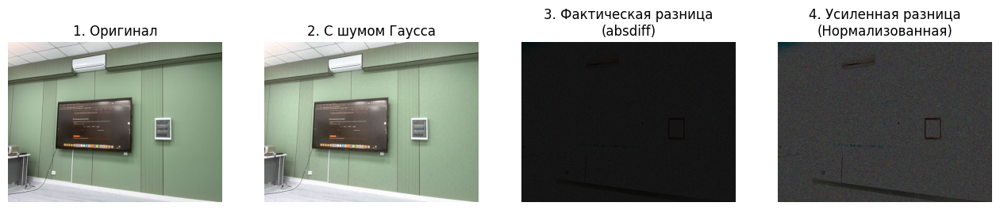

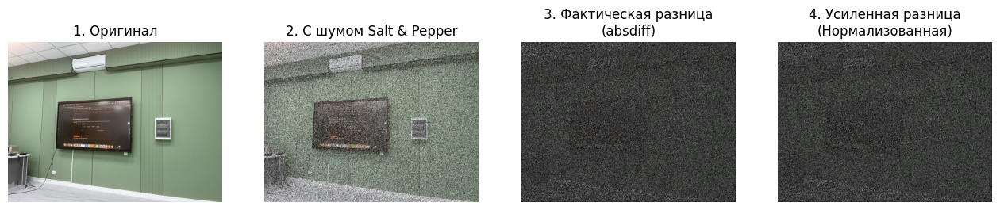

In [40]:
import matplotlib.pyplot as plt

def add_gaussian_noise(image, mean=20, var=200):
    sigma = var ** 0.5
    gauss = np.random.normal(mean, sigma, image.shape).astype('float32')
    noisy = np.clip(image.astype('float32') + gauss, 0, 255)
    return noisy.astype(np.uint8)

def add_salt_and_pepper_noise(image, salt_prob=0.1, pepper_prob=0.1):
    noisy = image.copy()
    
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 255
    
    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 0
    return noisy

img_gauss = add_gaussian_noise(img_bgr)
diff_between_gauss_and_original = cv2.absdiff(img_bgr, img_gauss)
print("Difference between original and Gaussian noise image:", diff_between_gauss_and_original)


plt.tight_layout()
plt.show()
img_sp = add_salt_and_pepper_noise(img_bgr)
diff_between_sp_and_original = cv2.absdiff(img_bgr, img_sp)
print("Difference between original and Salt & Pepper noise image:", diff_between_sp_and_original)


# 5. Отрисовка с помощью Matplotlib
plt.figure(figsize=(16, 8))

plt.subplot(1, 4, 1)
plt.title("1. Оригинал")
plt.imshow(img_bgr)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title("2. С шумом Гаусса")
plt.imshow(img_gauss)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title("3. Фактическая разница\n(absdiff)")
plt.imshow(diff_between_gauss_and_original)
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title("4. Усиленная разница\n(Нормализованная)")
plt.imshow(cv2.normalize(diff_between_gauss_and_original, None, 0, 255, cv2.NORM_MINMAX))
plt.axis('off')

# 5. Отрисовка с помощью Matplotlib
plt.figure(figsize=(16, 8))

plt.subplot(1, 4, 1)
plt.title("1. Оригинал")
plt.imshow(img_bgr)
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title("2. С шумом Salt & Pepper")
plt.imshow(img_sp)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title("3. Фактическая разница\n(absdiff)")
plt.imshow(diff_between_sp_and_original)
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title("4. Усиленная разница\n(Нормализованная)")
plt.imshow(cv2.normalize(diff_between_sp_and_original, None, 0, 255, cv2.NORM_MINMAX))
plt.axis('off')

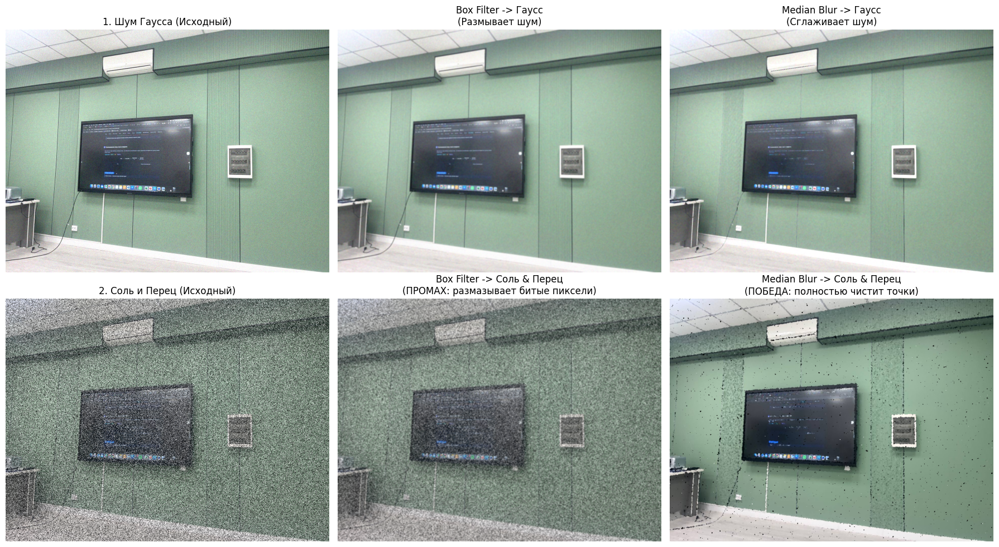

In [41]:



img_box_from_gauss = cv2.boxFilter(img_gauss, ddepth=-1, ksize=(5, 5))
img_box_from_salt_pepper = cv2.boxFilter(img_sp, ddepth=-1, ksize=(5, 5))
img_median_from_salt_pepper = cv2.medianBlur(img_sp, ksize=5)
img_median_from_gauss = cv2.medianBlur(img_gauss, ksize=5)



import cv2
import matplotlib.pyplot as plt

# Предполагается, что img_bgr, img_gauss и img_sp уже объявлены
# Если нужно перевести фильтры для BGR -> RGB:
img_bgr_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gauss_rgb = cv2.cvtColor(img_gauss, cv2.COLOR_BGR2RGB)
img_sp_rgb = cv2.cvtColor(img_sp, cv2.COLOR_BGR2RGB)

# Применение фильтров
img_box_from_gauss = cv2.boxFilter(img_gauss, ddepth=-1, ksize=(5, 5))
img_box_from_salt_pepper = cv2.boxFilter(img_sp, ddepth=-1, ksize=(5, 5))
img_median_from_gauss = cv2.medianBlur(img_gauss, ksize=5)
img_median_from_salt_pepper = cv2.medianBlur(img_sp, ksize=5)

# Конвертация результатов в RGB для корректного отображения
img_box_gauss_rgb = cv2.cvtColor(img_box_from_gauss, cv2.COLOR_BGR2RGB)
img_box_sp_rgb = cv2.cvtColor(img_box_from_salt_pepper, cv2.COLOR_BGR2RGB)
img_median_gauss_rgb = cv2.cvtColor(img_median_from_gauss, cv2.COLOR_BGR2RGB)
img_median_sp_rgb = cv2.cvtColor(img_median_from_salt_pepper, cv2.COLOR_BGR2RGB)

# Отрисовка сравнительной таблицы 2x3
plt.figure(figsize=(18, 10))

# --- Строка 1: Гауссов шум ---
plt.subplot(2, 3, 1)
plt.title("1. Шум Гаусса (Исходный)")
plt.imshow(img_gauss_rgb)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title("Box Filter -> Гаусс\n(Размывает шум)")
plt.imshow(img_box_gauss_rgb)
plt.axis('off')

plt.subplot(2, 3, 3)
plt.title("Median Blur -> Гаусс\n(Сглаживает шум)")
plt.imshow(img_median_gauss_rgb)
plt.axis('off')

# --- Строка 2: Шум Соль и Перец ---
plt.subplot(2, 3, 4)
plt.title("2. Соль и Перец (Исходный)")
plt.imshow(img_sp_rgb)
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title("Box Filter -> Соль & Перец\n(ПРОМАХ: размазывает битые пиксели)")
plt.imshow(img_box_sp_rgb)
plt.axis('off')

plt.subplot(2, 3, 6)
plt.title("Median Blur -> Соль & Перец\n(ПОБЕДА: полностью чистит точки)")
plt.imshow(img_median_sp_rgb)
plt.axis('off')

plt.tight_layout()
plt.show()



PSNR очищенного изображения: 22.53 dB


(0.0, 32.53389089600624)

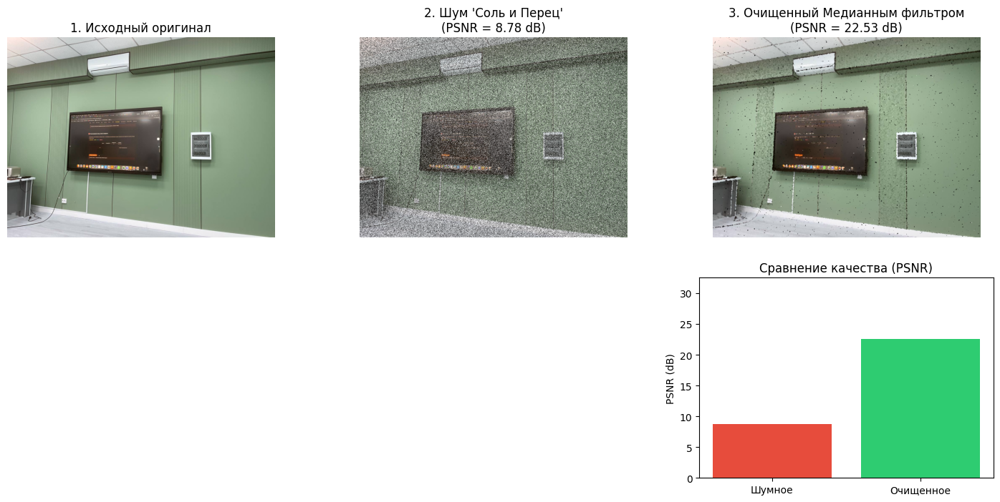

In [42]:

# 5. Оценка качества: PSNR (Peak Signal-to-Noise Ratio)
psnr_val = cv2.PSNR(img_bgr, img_median_from_salt_pepper)
print(f"PSNR очищенного изображения: {psnr_val:.2f} dB")
psnr_noisy = cv2.PSNR(img_bgr, img_sp)
psnr_cleaned = cv2.PSNR(img_bgr, img_median_from_salt_pepper)
fig = plt.figure(figsize=(18, 8))
diff_median_rgb = cv2.cvtColor(cv2.absdiff(img_bgr, img_median_from_salt_pepper), cv2.COLOR_BGR2RGB)
diff_median_enhanced_rgb = cv2.normalize(diff_median_rgb, None, 0, 255, cv2.NORM_MINMAX)
plt.subplot(2, 3, 1)
plt.title("1. Исходный оригинал")
plt.imshow(img_bgr)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title(f"2. Шум 'Соль и Перец'\n(PSNR = {psnr_noisy:.2f} dB)")
plt.imshow(img_sp)
plt.axis('off')

plt.subplot(2, 3, 3)
plt.title(f"3. Очищенный Медианным фильтром\n(PSNR = {psnr_cleaned:.2f} dB)")
plt.imshow(img_median_from_salt_pepper  )
plt.axis('off')


# График метрики PSNR
plt.subplot(2, 3, 6)
bars = plt.bar(['Шумное', 'Очищенное'], [psnr_noisy, psnr_cleaned], color=['#e74c3c', '#2ecc71'])
plt.ylabel('PSNR (dB)')
plt.title('Сравнение качества (PSNR)')
plt.ylim(0, max(psnr_noisy, psnr_cleaned) + 10)

In [43]:


gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

_, thresh_binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

thresh_adaptive = cv2.adaptiveThreshold(
    gray, 
    maxValue=255, 
    adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    thresholdType=cv2.THRESH_BINARY, 
    blockSize=11, 
    C=2
)

contours, hierarchy = cv2.findContours(
    thresh_adaptive, 
    mode=cv2.RETR_TREE, 
    method=cv2.CHAIN_APPROX_SIMPLE
)

img_contours = img_bgr.copy()
cv2.drawContours(img_contours, contours, contourIdx=-1, color=(0, 255, 0), thickness=2)

# Сохранение результата
cv2.imwrite('output_contours.jpg', img_contours)


True

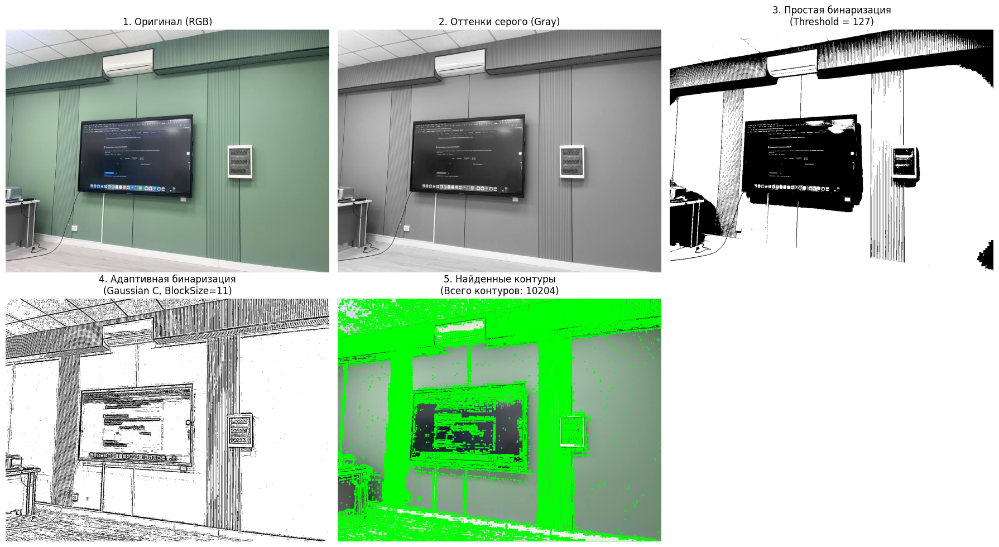

In [44]:
img_contours = img_bgr.copy()
cv2.drawContours(img_contours, contours, contourIdx=-1, color=(0, 255, 0), thickness=2)

# 6. Перевод BGR -> RGB для Matplotlib
img_bgr_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_contours_rgb = cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB)

# 7. Визуализация всех этапов
plt.figure(figsize=(18, 10))

# 1. Оригинал
plt.subplot(2, 3, 1)
plt.title("1. Оригинал (RGB)")
plt.imshow(img_bgr_rgb)
plt.axis('off')

# 2. Градации серого
plt.subplot(2, 3, 2)
plt.title("2. Оттенки серого (Gray)")
plt.imshow(gray, cmap='gray')
plt.axis('off')

# 3. Простая бинаризация
plt.subplot(2, 3, 3)
plt.title("3. Простая бинаризация\n(Threshold = 127)")
plt.imshow(thresh_binary, cmap='gray')
plt.axis('off')

# 4. Адаптивная бинаризация
plt.subplot(2, 3, 4)
plt.title("4. Адаптивная бинаризация\n(Gaussian C, BlockSize=11)")
plt.imshow(thresh_adaptive, cmap='gray')
plt.axis('off')

# 5. Итоговые контуры
plt.subplot(2, 3, 5)
plt.title(f"5. Найденные контуры\n(Всего контуров: {len(contours)})")
plt.imshow(img_contours_rgb)
plt.axis('off')

plt.tight_layout()
plt.show()

In [45]:
booklet = cv2.imread('booklet.jpg')
booklet_gray = cv2.cvtColor(booklet, cv2.COLOR_BGR2GRAY)
booklet_blured_gray = cv2.GaussianBlur(booklet_gray, (5, 5), 0)

_, thresh_binary = cv2.threshold(booklet_blured_gray, 190, 255, cv2.THRESH_BINARY)

thresh_adaptive = cv2.adaptiveThreshold(
    booklet_blured_gray, 
    maxValue=255, 
    adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    thresholdType=cv2.THRESH_BINARY, 
    blockSize=11, 
    C=10
)

contours, hierarchy = cv2.findContours(
    thresh_adaptive, 
    mode=cv2.RETR_TREE, 
    method=cv2.CHAIN_APPROX_SIMPLE
)

img_contours = booklet.copy()
cv2.drawContours(img_contours, contours, contourIdx=-1, color=(0, 255, 0), thickness=2)

cv2.imwrite('output_contours.jpg', img_contours)





True

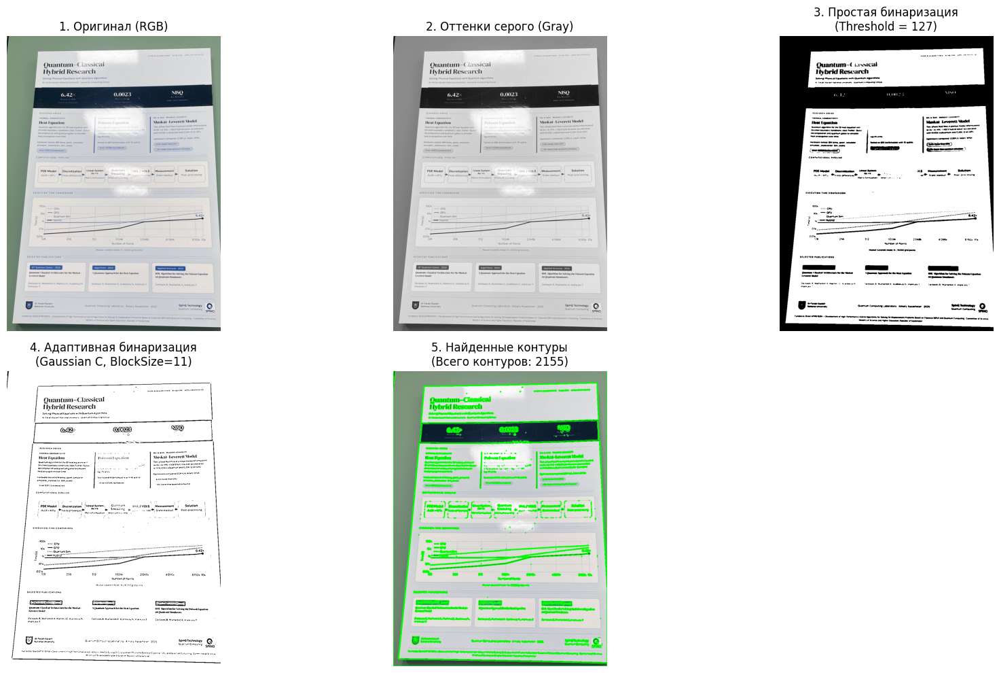

In [46]:
img_contours = booklet.copy()
cv2.drawContours(img_contours, contours, contourIdx=-1, color=(0, 255, 0), thickness=2)

# 6. Перевод BGR -> RGB для Matplotlib
booklet_rgb = cv2.cvtColor(booklet, cv2.COLOR_BGR2RGB)
img_contours_rgb = cv2.cvtColor(img_contours, cv2.COLOR_BGR2RGB)

# 7. Визуализация всех этапов
plt.figure(figsize=(18, 10))

# 1. Оригинал
plt.subplot(2, 3, 1)
plt.title("1. Оригинал (RGB)")
plt.imshow(booklet_rgb)
plt.axis('off')

# 2. Градации серого
plt.subplot(2, 3, 2)
plt.title("2. Оттенки серого (Gray)")
plt.imshow(booklet_gray, cmap='gray')
plt.axis('off')

# 3. Простая бинаризация
plt.subplot(2, 3, 3)
plt.title("3. Простая бинаризация\n(Threshold = 127)")
plt.imshow(thresh_binary, cmap='gray')
plt.axis('off')

# 4. Адаптивная бинаризация
plt.subplot(2, 3, 4)
plt.title("4. Адаптивная бинаризация\n(Gaussian C, BlockSize=11)")
plt.imshow(thresh_adaptive, cmap='gray')
plt.axis('off')

# 5. Итоговые контуры
plt.subplot(2, 3, 5)
plt.title(f"5. Найденные контуры\n(Всего контуров: {len(contours)})")
plt.imshow(img_contours_rgb)
plt.axis('off')

plt.tight_layout()
plt.show()

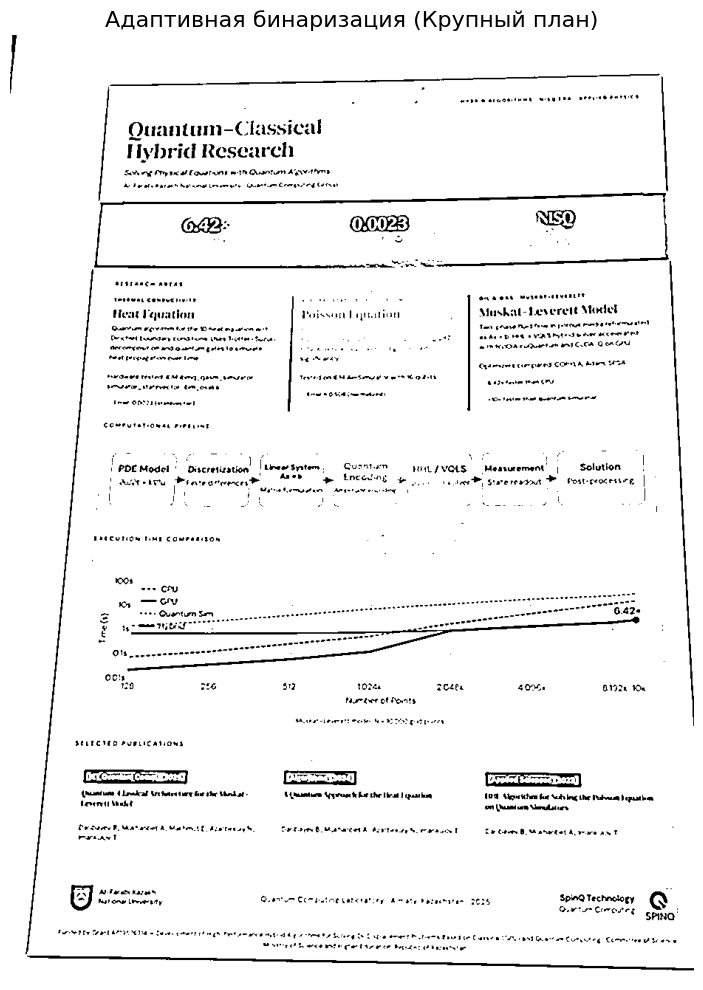

In [47]:
# 4. Адаптивная бинаризация
# Выводим в отдельном КРУПНОМ холсте
plt.figure(figsize=(14, 10))  # Увеличиваем размер холста
plt.title("Адаптивная бинаризация (Крупный план)", fontsize=16)
plt.imshow(thresh_adaptive, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

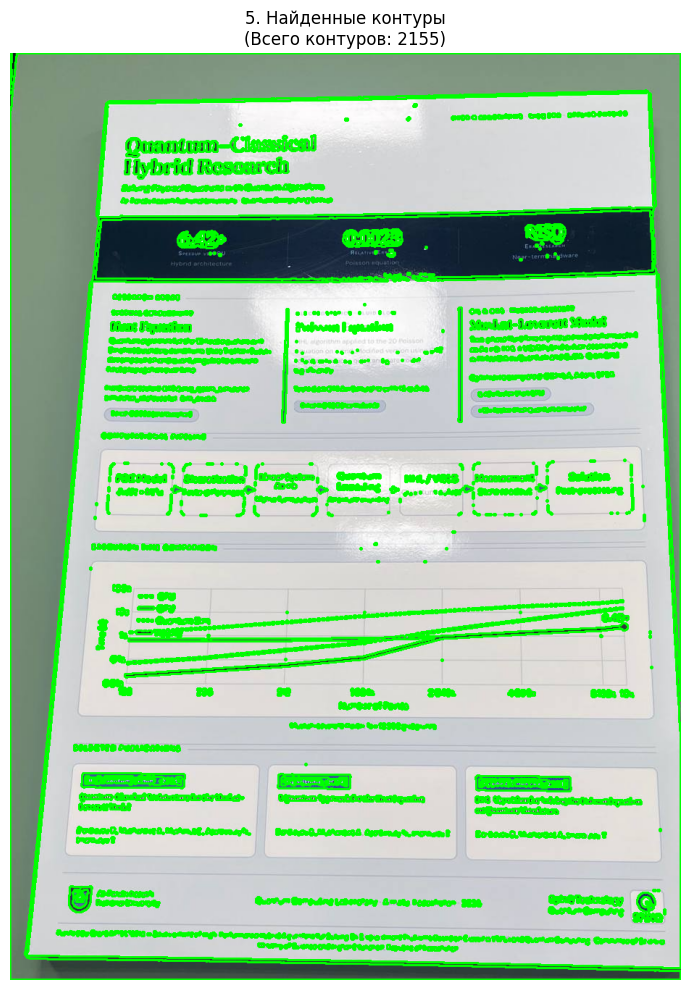

In [48]:
# 4. Адаптивная бинаризация
# Выводим в отдельном КРУПНОМ холсте
plt.figure(figsize=(14, 10))  # Увеличиваем размер холста
plt.title(f"5. Найденные контуры\n(Всего контуров: {len(contours)})")
plt.imshow(img_contours_rgb, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

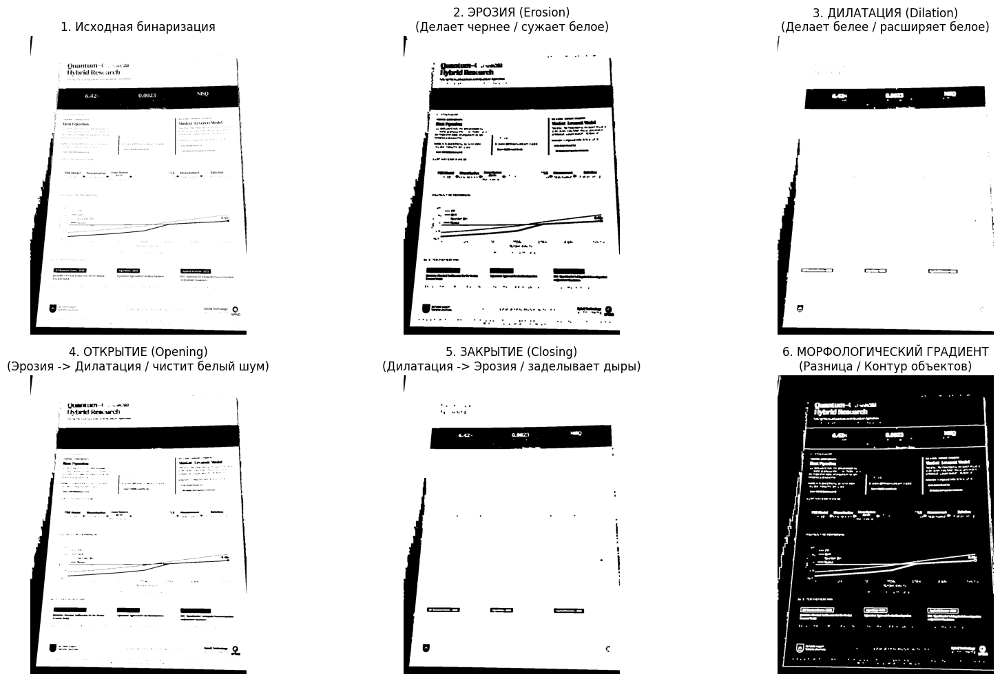

In [49]:
# 1. Загрузка в оттенках серого и получение бинарного изображения
img_bgr = cv2.imread('booklet.jpg')
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 2. Задание ядра (структурного элемента). Чем больше ядро, тем сильнее эффект!
kernel = np.ones((5, 5), np.uint8)

# 3. Применение морфологических операций

# Эрозия (Делает чернее / съедает белый цвет)
erosion = cv2.erode(thresh, kernel, iterations=1)

# Дилатация (Делает белее / расширяет белый цвет)
dilation = cv2.dilate(thresh, kernel, iterations=1)

# Открытие (Убирает мелкие белые точки)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

# Закрытие (Заделывает черные дыры внутри белого)
closing = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

# Градиент (Выделяет границы: Дилатация - Эрозия)
gradient = cv2.morphologyEx(thresh, cv2.MORPH_GRADIENT, kernel)


plt.figure(figsize=(18, 10))

plt.subplot(2, 3, 1)
plt.title("1. Исходная бинаризация")
plt.imshow(thresh, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.title("2. ЭРОЗИЯ (Erosion)\n(Делает чернее / сужает белое)")
plt.imshow(erosion, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.title("3. ДИЛАТАЦИЯ (Dilation)\n(Делает белее / расширяет белое)")
plt.imshow(dilation, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.title("4. ОТКРЫТИЕ (Opening)\n(Эрозия -> Дилатация / чистит белый шум)")
plt.imshow(opening, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title("5. ЗАКРЫТИЕ (Closing)\n(Дилатация -> Эрозия / заделывает дыры)")
plt.imshow(closing, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.title("6. МОРФОЛОГИЧЕСКИЙ ГРАДИЕНТ\n(Разница / Контур объектов)")
plt.imshow(gradient, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()